# Machine Learning Model Development

## Objective

This notebook develops predictive machine learning models for the mechanical
properties of natural fibre composites.

Two prediction tasks are investigated:

1. Predicting Tensile Strength
2. Predicting Elastic Modulus

Several regression algorithms are compared:

- Linear Regression
- Random Forest Regression
- Gradient Boosting Regression
- XGBoost Regression
- CatBoost Regression

Model performance will be evaluated using:

- R² Score
- RMSE
- MAE

In [3]:
# Data handling

import pandas as pd
import numpy as np


# Visualisation

import matplotlib.pyplot as plt


# Machine learning tools

from sklearn.model_selection import train_test_split


from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder


from sklearn.pipeline import Pipeline


# Models

from sklearn.linear_model import LinearRegression


from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)


from xgboost import XGBRegressor


from catboost import CatBoostRegressor


# Evaluation

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import joblib
import warnings

warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("../data/cleaned/cleaned_dataset.csv")
df.head()

,fiber_type,matrix_type,fiber_configuration,orientation,num_plies,fiber_volume_fraction,elastic_modulus_mpa,tensile_strength_mpa
0,Flax,Epoxy,0,0 UD,3.0,0.3,20042.2367,297.4065
1,Flax,Epoxy,0,0 UD,3.0,0.3,19701.1091,289.9346
2,Flax,Epoxy,0,0 UD,3.0,0.3,17559.1106,274.8862
3,Flax,Epoxy,0,0 UD,3.0,0.3,19737.9379,277.5509
4,Flax,Epoxy,0,0 UD,3.0,0.3,18048.3804,286.1064


In [5]:
df.shape

(581, 8)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 581 entries, 0 to 580
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   fiber_type             581 non-null    str    
 1   matrix_type            581 non-null    str    
 2   fiber_configuration    581 non-null    str    
 3   orientation            581 non-null    str    
 4   num_plies              581 non-null    float64
 5   fiber_volume_fraction  581 non-null    float64
 6   elastic_modulus_mpa    581 non-null    float64
 7   tensile_strength_mpa   581 non-null    float64
dtypes: float64(4), str(4)
memory usage: 36.4 KB


In [7]:
df.isnull().sum()

fiber_type               0
matrix_type              0
fiber_configuration      0
orientation              0
num_plies                0
fiber_volume_fraction    0
elastic_modulus_mpa      0
tensile_strength_mpa     0
dtype: int64

In [8]:
features = [
    "fiber_type",
    "matrix_type",
    "fiber_volume_fraction",
    "num_plies",
    "orientation",
    "fiber_configuration"
]

In [9]:
target_strength = "tensile_strength_mpa"

In [10]:
target_modulus = "elastic_modulus_mpa"

In [11]:
categorical_features = [
    "fiber_type",
    "matrix_type",
    "orientation",
    "fiber_configuration"
]


numerical_features = [
    "fiber_volume_fraction",
    "num_plies"
]

In [12]:
preprocessor = ColumnTransformer(

    transformers=[

        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )

    ],

    remainder="passthrough"

)

In [13]:
models = {

    "Linear Regression":
        LinearRegression(),


    "Random Forest":
        RandomForestRegressor(
            n_estimators=300,
            random_state=42
        ),


    "Gradient Boosting":
        GradientBoostingRegressor(
            random_state=42
        ),


    "XGBoost":
        XGBRegressor(
            n_estimators=300,
            random_state=42
        ),


    "CatBoost":
        CatBoostRegressor(
            iterations=300,
            verbose=0,
            random_state=42
        )

}

# PART A — Tensile Strength Prediction

In [14]:
X = df[features]

y_strength = df[target_strength]

In [15]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y_strength,

    test_size=0.2,

    random_state=42

)

In [16]:
strength_results = []


for name, model in models.items():

    pipeline = Pipeline(

        steps=[

            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                model
            )

        ]

    )


    pipeline.fit(
        X_train,
        y_train
    )


    predictions = pipeline.predict(
        X_test
    )


    r2 = r2_score(
        y_test,
        predictions
    )


    mae = mean_absolute_error(
        y_test,
        predictions
    )


    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )


    strength_results.append(

        [
            name,
            r2,
            mae,
            rmse
        ]

    )

In [17]:
strength_results_df = pd.DataFrame(

    strength_results,

    columns=[

        "Model",
        "R2",
        "MAE",
        "RMSE"

    ]

)


strength_results_df.sort_values(

    by="R2",

    ascending=False

)

,Model,R2,MAE,RMSE
3,XGBoost,0.983039,6.725245,10.751317
2,Gradient Boosting,0.974696,7.476290,13.132041
0,Linear Regression,0.971974,7.289204,13.820323
4,CatBoost,0.960329,8.286483,16.442729
1,Random Forest,0.944052,8.505416,19.526737


# Elastic Modulus Prediction

In [18]:
y_modulus = df[target_modulus]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y_modulus,

    test_size=0.2,

    random_state=42

)

In [20]:
modulus_results = []


for name, model in models.items():

    pipeline = Pipeline(

        steps=[

            (
                "preprocessor",
                preprocessor
            ),

            (
                "model",
                model
            )

        ]

    )


    pipeline.fit(
        X_train,
        y_train
    )


    predictions = pipeline.predict(
        X_test
    )


    r2 = r2_score(
        y_test,
        predictions
    )


    mae = mean_absolute_error(
        y_test,
        predictions
    )


    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )


    modulus_results.append(

        [
            name,
            r2,
            mae,
            rmse
        ]

    )

In [21]:
modulus_results_df = pd.DataFrame(

    modulus_results,

    columns=[

        "Model",
        "R2",
        "MAE",
        "RMSE"

    ]

)


modulus_results_df.sort_values(

    by="R2",

    ascending=False

)

,Model,R2,MAE,RMSE
3,XGBoost,0.948425,640.482583,1005.138318
0,Linear Regression,0.944302,631.035113,1044.546475
2,Gradient Boosting,0.935302,665.699541,1125.774683
4,CatBoost,0.927884,690.458968,1188.566826
1,Random Forest,0.903444,715.050367,1375.293807


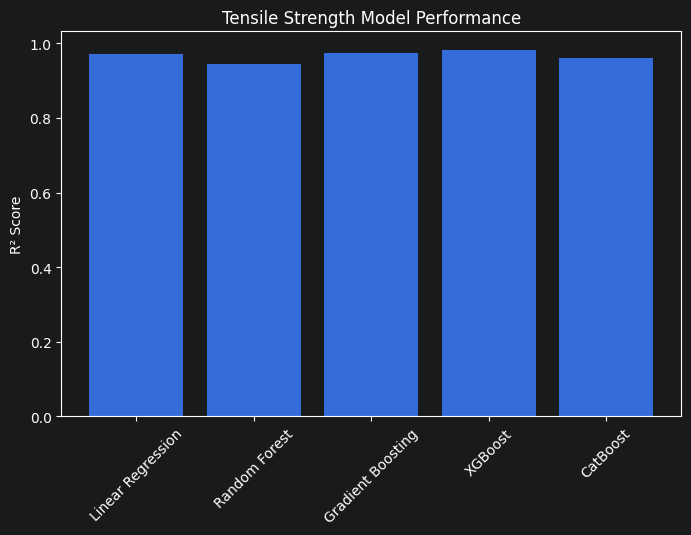

In [22]:
plt.figure(figsize=(8,5))


plt.bar(

    strength_results_df["Model"],

    strength_results_df["R2"]

)


plt.xticks(
    rotation=45
)


plt.ylabel(
    "R² Score"
)


plt.title(
    "Tensile Strength Model Performance"
)


plt.show()

In [23]:
import joblib

In [24]:
best_strength_model_name = (
    strength_results_df
    .sort_values(
        by="R2",
        ascending=False
    )
    .iloc[0]["Model"]
)


print(
    "Best Tensile Strength Model:",
    best_strength_model_name
)

Best Tensile Strength Model: XGBoost


In [25]:
best_strength_model = models[
    best_strength_model_name
]


strength_pipeline = Pipeline(

    steps=[

        (
            "preprocessor",
            preprocessor
        ),

        (
            "model",
            best_strength_model
        )

    ]

)


strength_pipeline.fit(
    X,
    y_strength
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['fiber_type','matrix_type','fiber_volume_fraction','num_plies', 'orientation','fiber_configuration']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. 

In [26]:
joblib.dump(
    strength_pipeline,
    "../models/tensile_strength_model.pkl"
)

['../models/tensile_strength_model.pkl']

In [27]:
best_modulus_model_name = (
    modulus_results_df
    .sort_values(
        by="R2",
        ascending=False
    )
    .iloc[0]["Model"]
)


print(
    "Best Elastic Modulus Model:",
    best_modulus_model_name
)

Best Elastic Modulus Model: XGBoost


In [28]:
best_modulus_model = models[
    best_modulus_model_name
]


modulus_pipeline = Pipeline(

    steps=[

        (
            "preprocessor",
            preprocessor
        ),

        (
            "model",
            best_modulus_model
        )

    ]

)


modulus_pipeline.fit(
    X,
    y_modulus
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['fiber_type','matrix_type','fiber_volume_fraction','num_plies', 'orientation','fiber_configuration']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. 

In [29]:
joblib.dump(
    modulus_pipeline,
    "../models/elastic_modulus_model.pkl"
)

['../models/elastic_modulus_model.pkl']

In [30]:
loaded_strength_model = joblib.load(
    "../models/tensile_strength_model.pkl"
)


loaded_modulus_model = joblib.load(
    "../models/elastic_modulus_model.pkl"
)

In [31]:
sample = pd.DataFrame({

    "fiber_type": ["Flax"],

    "matrix_type": ["Epoxy"],

    "fiber_volume_fraction": [40],

    "num_plies": [5],

    "orientation": ["0"],

    "fiber_configuration": ["Unidirectional"]

})

In [32]:
strength_prediction = loaded_strength_model.predict(sample)

modulus_prediction = loaded_modulus_model.predict(sample)


print(
    "Predicted Tensile Strength:",
    strength_prediction[0],
    "MPa"
)


print(
    "Predicted Elastic Modulus:",
    modulus_prediction[0],
    "MPa"
)

Predicted Tensile Strength: 86.59314 MPa
Predicted Elastic Modulus: 5155.2554 MPa
